In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tqdm
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import gaussian_kde

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman"],
                     "mathtext.fontset": "stix"})

DATA_DIR = "../data"
FIG_DIR = "../figures"
RAW_STORES = {                                   # written by notebook 1 (order = row order)
    "Women": os.path.join(DATA_DIR, "women-statsbomb3.h5"),
    "Men":   os.path.join(DATA_DIR, "men-statsbomb.h5"),
}
OUT_H5 = os.path.join(DATA_DIR, "ppi-features.h5")
os.makedirs(FIG_DIR, exist_ok=True)

TOURNAMENTS = {                                  # (competition_id, season_id) → label
    (55, 43): "EURO2020", (43, 106): "WC2022",  (55, 282): "EURO2024",
    (53, 106): "WEURO2022", (72, 107): "WWC2023", (53, 315): "WEURO2025",
}

## 1 · Possession-level PoP variables (Table 1)

The unit of analysis is the provider's possession (`possession`, `possession_team_id`).
The possession window spans the events of both teams; possessions shorter than 3 s, or
crossing a period break, are dropped. StatsBomb pitch units (yards) are converted to metres.

Variables are grouped into the three conceptual dimensions of Table 1. Code names that differ
from the manuscript: `distance_per_second` = ball displacement per second, `distance_per_touch` =
ball displacement per touch, `time_to_pass` = inter-pass interval, `team_spread_rate` = team
spread ratio change rate, `spatial_compression_x / _y` = longitudinal / lateral **spatial spread**
(SD of attacker positions; higher = more spread). `ball_speed_per_touch` is the
Hamilton (2013) baseline; the other three baselines (passes per minute, ball displacement per
second, inter-pass interval) are, by definition, identical to the PoP variables of the same name.

In [2]:
# ── Pitch / event constants (possession team always attacks towards x = 120) ──
YD2M = 0.9144                                    # StatsBomb units are yards
ATT_THIRD_X = 80.0                               # start of the attacking third (yards)
GOAL_CENTRE_M = np.array([120.0, 40.0]) * YD2M   # centre of the opponent's goal line
HALFWAY_X_M = 60.0 * YD2M

MIN_POSSESSION_S = 3.0      # shorter possessions are dropped
MAX_ELAPSED_S = 90.0        # cap for "time from possession start to X"
MIN_FRAME_DT_S = 0.1        # min gap between 360 frames for centroid speed
MAX_CENTROID_SPEED = 12.0   # yards·s⁻¹; faster = tracking artefact

EXCLUDE_TYPES = {"Starting XI", "Half Start", "Half End", "Tactical Shift",
                 "Substitution", "Bad Behaviour", "Referee Ball-Drop"}
TOUCH_TYPES = {"Pass", "Carry", "Shot", "Dribble", "Ball Recovery", "Clearance",
               "Interception", "Miscontrol", "Dispossessed", "Block"}
DEFENSIVE_TYPES = {"Pressure", "Duel", "Block", "Interception", "Clearance", "Ball Recovery"}
# event types ignored for ball displacement per second (Epasinghege Dona & Swartz, 2023)
DISPLACEMENT_EXCLUDE = {"Starting XI", "Half Start", "Pressure", "Miscontrol", "Tactical Shift",
                        "Half End", "Player Off", "Substitution", "Foul Won", "Dribbled Past",
                        "Shield", "Bad Behaviour"}
# ball touches for ball speed per touch (Hamilton, 2013)
HAMILTON_TOUCHES = {"Pass", "Carry", "Clearance", "Dribble", "Shot", "Goal Keeper", "Interception"}

METRIC_GROUPS = {
    "Activity intensity": ["passes_per_minute", "distance_per_second", "distance_per_touch",
                           "pressing_frequency"],
    "Directional intent": ["attacking_transition_time", "team_centroid_speed",
                           "forward_progression_rate", "progressive_action_rate",
                           "opponents_bypassed_per_second", "goal_directed_displacement_per_second"],
    "Constraint":         ["spatial_compression_x", "spatial_compression_y",
                           "defensive_line_variability", "time_to_pass", "pass_completion_rate",
                           "team_spread_rate", "inter_team_longitudinal_dist"],
}
# computed in yards, converted to metres on output
LENGTH_COLS = ["distance_per_second", "distance_per_touch", "team_centroid_speed",
               "inter_team_longitudinal_dist", "spatial_compression_x", "spatial_compression_y",
               "ball_speed_per_touch"]


# ── Small utilities ───────────────────────────────────────────────────────────
def _safe_div(num, den):
    return num / den if den > 0 else np.nan


def _mean_or_nan(values):
    return float(np.mean(values)) if len(values) else np.nan


def _xy(loc):
    return (loc[0], loc[1]) if isinstance(loc, list) else (np.nan, np.nan)


def parse_sub(extra, event_type):
    """Event-specific sub-dict (pass / carry / shot) of the `extra` field."""
    key = {"Pass": "pass", "Carry": "carry", "Shot": "shot"}.get(event_type)
    sub = extra.get(key) if isinstance(extra, dict) and key else None
    return sub if isinstance(sub, dict) else {}


def _is_failed_pass(extra):
    return isinstance(extra, dict) and "outcome" in extra.get("pass", {})


def parse_freeze_frame(ff):
    """Outfield player locations (goalkeepers excluded) of a 360 freeze frame.

    Returns (attackers, defenders) relative to the event's actor team."""
    att, dfn = [], []
    if not isinstance(ff, list):
        return att, dfn
    for p in ff:
        loc = p.get("location")
        if not (isinstance(loc, list) and len(loc) >= 2) or p.get("keeper", False):
            continue
        (att if p.get("teammate", False) else dfn).append(loc[:2])
    return att, dfn


# ── Possession-level building blocks ──────────────────────────────────────────
def _possession_window(grp):
    """(t_start, T_p) over both teams' events, or None if the possession is dropped."""
    if grp["period_id"].nunique() > 1:           # timestamps reset at each period
        return None
    t_start = grp["time_s"].min()
    T_p = grp["time_s"].max() - t_start
    return (t_start, T_p) if T_p >= MIN_POSSESSION_S else None


def _elapsed(t_event, t_start):
    if np.isnan(t_event):
        return np.nan
    dt = t_event - t_start
    return dt if dt <= MAX_ELAPSED_S else np.nan


def compute_ball_distances(att):
    """Possession-team ball travel from passes (pass.length) and carries.

    D_t: total Euclidean travel; D_f: forward travel Σ max(Δx, 0); D_x: Σ |Δx|."""
    p_len, p_dx, c_len, c_dx = [], [], [], []
    for typ, loc, ex in zip(att["type_name"], att["location"], att["extra"]):
        if typ not in ("Pass", "Carry"):
            continue
        sub = parse_sub(ex, typ)
        end = sub.get("end_location")
        dx = dy = 0.0
        if isinstance(end, list) and isinstance(loc, list):
            dx, dy = end[0] - loc[0], end[1] - loc[1]
        if typ == "Pass":
            p_len.append(sub.get("length", 0.0) or 0.0)
            p_dx.append(dx)
        else:
            c_len.append(np.hypot(dx, dy))
            c_dx.append(dx)
    dxs = np.asarray(p_dx + c_dx, dtype=float)
    D_t = float(np.sum(np.asarray(p_len, dtype=float)) + np.sum(np.asarray(c_len, dtype=float)))
    return D_t, float(np.maximum(dxs, 0.0).sum()), float(np.abs(dxs).sum())


def _scan_freeze_frames(att):
    """Per-frame shape descriptors from the possession team's 360 frames."""
    fr = {k: [] for k in ("centroid", "centroid_t", "sd_x", "sd_y", "shape_ratio",
                          "shape_t", "def_last_x", "inter_team_dx")}
    att_360 = att[att["freeze_frame_360"].notna()]
    for ff, t in zip(att_360["freeze_frame_360"], att_360["time_s"].astype(float)):
        att_field, def_field = parse_freeze_frame(ff)
        has_att, has_def = len(att_field) >= 2, len(def_field) >= 2
        if has_att:
            xy = np.asarray(att_field, dtype=float)
            xs, ys = xy[:, 0], xy[:, 1]
            fr["centroid"].append(xy.mean(axis=0))
            fr["centroid_t"].append(t)
            fr["sd_x"].append(float(xs.std()))
            fr["sd_y"].append(float(ys.std()))
            width = float(ys.max() - ys.min())
            if width > 0:
                fr["shape_ratio"].append(float(xs.max() - xs.min()) / width)
                fr["shape_t"].append(t)
        if has_def:
            def_xs = np.asarray(def_field, dtype=float)[:, 0]
            fr["def_last_x"].append(float(def_xs.max()))
            if has_att:
                fr["inter_team_dx"].append(float(def_xs.mean() - xs.mean()))
    return fr


def _centroid_speed(centroids, times):
    if len(centroids) < 2:
        return np.nan
    dt = np.diff(np.asarray(times, dtype=float))
    d = np.linalg.norm(np.diff(np.asarray(centroids, dtype=float), axis=0), axis=1)
    ok = dt > MIN_FRAME_DT_S
    speeds = d[ok] / dt[ok]
    return _mean_or_nan(speeds[speeds < MAX_CENTROID_SPEED])


def _cv(values):
    if len(values) < 2:
        return np.nan
    a = np.asarray(values, dtype=float)
    return float(a.std() / a.mean()) if a.mean() != 0 else np.nan


def _spread_rate(vals, times):
    """Mean |Δ(length / width) / Δt| of the attacking block."""
    if len(vals) < 2:
        return np.nan
    dt = np.diff(np.asarray(times, dtype=float))
    ok = dt > 0
    rate = np.abs(np.diff(np.asarray(vals, dtype=float))[ok] / dt[ok])
    rate = rate[rate < 10.0]
    return _mean_or_nan(rate)


def _time_to_attacking_third(att):
    """Time of the first possession-team event in the attacking third; NaN if the
    possession started there or never reached it."""
    first_loc = att["location"].iloc[0]
    if not (isinstance(first_loc, list) and len(first_loc) > 0 and first_loc[0] <= ATT_THIRD_X):
        return np.nan
    in_att3 = att["location"].apply(lambda loc: isinstance(loc, list) and loc[0] > ATT_THIRD_X)
    return att.loc[in_att3, "time_s"].min() if in_att3.any() else np.nan


def _inter_pass_interval(grp, team_id):
    """Bransen & Davis (2025): mean time between each possession-team pass and the preceding
    teammate pass or same-player interception (0–30 s)."""
    grp = grp.reset_index(drop=True)
    deltas = []
    for i in np.flatnonzero((grp["type_name"] == "Pass") & (grp["team_id"] == team_id)):
        cur, prev = grp.iloc[i], grp.iloc[:i]
        eligible = prev[((prev["type_name"] == "Pass") & (prev["team_id"] == cur["team_id"])
                         & (prev["player_id"] != cur["player_id"]))
                        | ((prev["type_name"] == "Interception")
                           & (prev["player_id"] == cur["player_id"]))]
        if len(eligible) == 0:
            continue
        delta = cur["time_s"] - eligible["time_s"].iloc[-1]
        if 0 <= delta <= 30:
            deltas.append(delta)
    return _mean_or_nan(deltas)


def _team_frame_xy(events, team_id):
    """x / y of events, with the defending team's events mirrored into the possession
    team's frame of reference."""
    x, y = zip(*[_xy(loc) for loc in events["location"]]) if len(events) else ((), ())
    ev = events.assign(x=np.asarray(x, dtype=float), y=np.asarray(y, dtype=float))
    ev = ev.dropna(subset=["x", "y"]).reset_index(drop=True)
    opp = (ev["team_id"] != team_id).to_numpy()
    ev["x_u"] = np.where(opp, 120 - ev["x"], ev["x"])
    ev["y_u"] = np.where(opp, 80 - ev["y"], ev["y"])
    return ev


def _distance_per_second(grp, team_id):
    """Epasinghege Dona & Swartz (2023) general pace: Σ distance between consecutive
    events (both teams) / elapsed time."""
    ev = _team_frame_xy(grp[~grp["type_name"].isin(DISPLACEMENT_EXCLUDE)], team_id)
    if len(ev) < 3:
        return np.nan
    dist = float(np.linalg.norm(np.diff(ev[["x_u", "y_u"]].to_numpy(), axis=0), axis=1).sum())
    dur = ((ev["minute"].iloc[-1] + ev["second"].iloc[-1] / 60)
           - (ev["minute"].iloc[0] + ev["second"].iloc[0] / 60)) * 60
    return dist / dur if dur > 0 else np.nan


def _ball_speed_per_touch(grp, team_id):
    """Hamilton (2013): Σ ball displacement / (N_touches · elapsed time). Passes, shots and
    carries use their end location, other touches the location of the next touch."""
    h = _team_frame_xy(grp[grp["type_name"].isin(HAMILTON_TOUCHES)], team_id)
    if len(h) < 2:
        return np.nan
    t_span = ((h["minute"].iloc[-1] * 60 + h["second"].iloc[-1])
              - (h["minute"].iloc[0] * 60 + h["second"].iloc[0]))
    if t_span <= 0:
        return np.nan
    total_d = 0.0
    for j, (typ, ex) in enumerate(zip(h["type_name"], h["extra"])):
        if typ in ("Pass", "Shot", "Carry"):
            end = parse_sub(ex, typ).get("end_location")
            if isinstance(end, list) and len(end) >= 2:
                total_d += float(np.hypot(end[0] - h["x"].iloc[j], end[1] - h["y"].iloc[j]))
        elif j < len(h) - 1:
            total_d += float(np.hypot(h["x_u"].iloc[j + 1] - h["x_u"].iloc[j],
                                      h["y_u"].iloc[j + 1] - h["y_u"].iloc[j]))
    return total_d / (len(h) * t_span)


def _is_progressive(x0, x1, gain):
    """Wyscout progressive action (metres): ≥ 30 m closer to goal within the own half,
    ≥ 15 m when crossing halves, ≥ 10 m within the opponent half."""
    own0, own1 = x0 < HALFWAY_X_M, x1 < HALFWAY_X_M
    if own0 and own1:
        return gain >= 30.0
    return gain >= (15.0 if own0 != own1 else 10.0)


def _directional_rates(att, T_p):
    """Goal-directed displacement, progressive actions and opponents bypassed per unit time,
    from the possession team's completed passes and carries."""
    gain_sum, n_prog, n_bypass = 0.0, 0, 0
    for typ, loc, ex, ff in zip(att["type_name"], att["location"], att["extra"],
                                att["freeze_frame_360"]):
        if typ not in ("Pass", "Carry") or not isinstance(loc, list):
            continue
        sub = parse_sub(ex, typ)
        end = sub.get("end_location")
        if not isinstance(end, list) or (typ == "Pass" and "outcome" in sub):
            continue                              # incomplete pass
        p0 = np.asarray(loc[:2], dtype=float) * YD2M
        p1 = np.asarray(end[:2], dtype=float) * YD2M
        gain = np.linalg.norm(GOAL_CENTRE_M - p0) - np.linalg.norm(GOAL_CENTRE_M - p1)
        gain_sum += gain
        n_prog += _is_progressive(p0[0], p1[0], gain)
        if typ == "Pass" and p1[0] > p0[0]:        # forward pass: outfield defenders passed
            _, def_field = parse_freeze_frame(ff)
            n_bypass += sum(p0[0] < x * YD2M < p1[0] for x, _ in def_field)
    return {
        "goal_directed_displacement_per_second": gain_sum / T_p,      # m·s⁻¹
        "progressive_action_rate": 60.0 * n_prog / T_p,                # min⁻¹
        "opponents_bypassed_per_second": n_bypass / T_p,               # s⁻¹
    }

In [3]:
def compute_pace_metrics(events):
    """All Table 1 variables (+ Hamilton baseline) for one match; one row per possession."""
    events = events[~events["type_name"].isin(EXCLUDE_TYPES)].copy()
    events["time_s"] = events["timestamp"].dt.total_seconds()

    rows = []
    for (poss_id, team_id), grp in events.groupby(["possession", "possession_team_id"], sort=False):
        grp = grp.sort_values("index")
        is_att = grp["team_id"] == team_id
        att, defe = grp[is_att], grp[~is_att]
        window = _possession_window(grp) if not att.empty else None
        if window is None:
            continue
        t_start, T_p = window
        D_t, D_f, D_x = compute_ball_distances(att)
        frames = _scan_freeze_frames(att)
        passes = att[att["type_name"] == "Pass"]
        n_passes = int((grp["type_name"] == "Pass").sum())          # both teams

        rows.append({
            "game_id": grp["game_id"].iloc[0], "possession": poss_id,
            "possession_team_id": team_id,
            "possession_team_name": grp["possession_team_name"].iloc[0],
            "period_id": grp["period_id"].iloc[0], "T_p": T_p, "N_passes": n_passes,
            # activity intensity
            "passes_per_minute": 60.0 * n_passes / T_p,
            "distance_per_second": _distance_per_second(grp, team_id),
            "distance_per_touch": _safe_div(D_t, int(att["type_name"].isin(TOUCH_TYPES).sum())),
            "pressing_frequency": int(defe["type_name"].isin(DEFENSIVE_TYPES).sum()) / T_p,
            # directional intent
            "attacking_transition_time": _elapsed(_time_to_attacking_third(att), t_start),
            "team_centroid_speed": _centroid_speed(frames["centroid"], frames["centroid_t"]),
            "forward_progression_rate": _safe_div(D_f, D_x),
            **_directional_rates(att, T_p),
            # constraint
            "spatial_compression_x": _mean_or_nan(frames["sd_x"]),
            "spatial_compression_y": _mean_or_nan(frames["sd_y"]),
            "defensive_line_variability": _cv(frames["def_last_x"]),
            "time_to_pass": _inter_pass_interval(grp, team_id),
            "pass_completion_rate": _safe_div(sum(not _is_failed_pass(e) for e in passes["extra"]),
                                              len(passes)),
            "team_spread_rate": _spread_rate(frames["shape_ratio"], frames["shape_t"]),
            "inter_team_longitudinal_dist": _mean_or_nan(frames["inter_team_dx"]),
            # baseline only (Hamilton, 2013)
            "ball_speed_per_touch": _ball_speed_per_touch(grp, team_id),
        })
    out = pd.DataFrame(rows)
    if len(out):
        out[LENGTH_COLS] = out[LENGTH_COLS] * YD2M                  # yards → metres
    return out


def possession_play_pattern(events):
    """Provider play pattern of each possession's first event (e.g. From Counter)."""
    cols = ["index", "possession", "possession_team_id", "play_pattern_name"]
    first = (events[cols].sort_values("index")
             .groupby(["possession", "possession_team_id"], as_index=False).first())
    return first[["possession", "possession_team_id", "play_pattern_name"]]


def process_store(sex, path):
    games = pd.read_hdf(path, "games")
    frames = []
    for g in tqdm.tqdm(list(games.itertuples()), desc=f"{sex} matches"):
        events = pd.read_hdf(path, f"events/game_{g.game_id}")
        feats = compute_pace_metrics(events).merge(
            possession_play_pattern(events), on=["possession", "possession_team_id"], how="left")
        frames.append(feats.assign(tournament=TOURNAMENTS[(g.competition_id, g.season_id)],
                                   sex=sex))
    return pd.concat(frames, ignore_index=True)


features = pd.concat([process_store(sex, path) for sex, path in RAW_STORES.items()],
                     ignore_index=True)
features.to_hdf(OUT_H5, key="features", mode="a", complevel=5)

print(f"Possessions ≥ {MIN_POSSESSION_S:.0f} s: {len(features):,} "
      f"from {features['game_id'].nunique()} matches")
print(features.groupby(["sex", "tournament"]).agg(matches=("game_id", "nunique"),
                                                  possessions=("game_id", "size")).to_string())
for group, cols in METRIC_GROUPS.items():
    print(f"\n=== {group} ===")
    print(features[cols].describe().T[["count", "mean", "std", "min", "max"]].round(3).to_string())

Men matches: 100%|██████████| 166/166 [01:28<00:00,  1.88it/s]


Possessions ≥ 3 s: 43,773 from 292 matches
                  matches  possessions
sex   tournament                      
Men   EURO2020         51         7439
      EURO2024         51         6953
      WC2022           64         9382
Women WEURO2022        31         4764
      WEURO2025        31         4838
      WWC2023          64        10397

=== Activity intensity ===
                       count    mean    std    min     max
passes_per_minute    43773.0  19.334  8.340  0.000  79.602
distance_per_second  42904.0   8.208  2.875  0.061  61.670
distance_per_touch   43725.0  13.780  9.805  0.000  98.810
pressing_frequency   43773.0   0.166  0.155  0.000   1.431

=== Directional intent ===
                                         count    mean     std    min     max
attacking_transition_time              20790.0  16.102  13.300  0.000  89.769
team_centroid_speed                    40410.0   3.818   1.341  0.058  10.963
forward_progression_rate               43635.0   0.762   0.2

## 2 · Standardisation

Structural missing values are imputed (inter-pass interval: possessions with fewer than two
eligible passes → 95th percentile; attacking transition time: possessions that start in the
attacking third → median); possessions with any other missing variable (mostly no 360 frame)
are dropped. Inter-pass interval and attacking transition time are sign-inverted so that higher
values indicate higher PoP. All variables are winsorised at [P1, P99] and z-standardised across
the sample (`Xz`, used for scoring).

The EFA and the Horst weights use the **pooled within-tournament correlation matrix**: the
variables are centred within each tournament (`X_within`) so that the correlations reflect how
the variables co-vary within a competition. Because each tournament contains one sex only, this
also removes the sex difference from the construction.

In [4]:
CANDIDATES = [
    "passes_per_minute", "distance_per_second", "distance_per_touch", "time_to_pass",
    "attacking_transition_time", "team_centroid_speed", "forward_progression_rate",
    "team_spread_rate", "inter_team_longitudinal_dist", "pressing_frequency",
    "spatial_compression_x", "spatial_compression_y", "defensive_line_variability",
    "pass_completion_rate", "goal_directed_displacement_per_second",
    "progressive_action_rate", "opponents_bypassed_per_second",
]
INVERT = ["time_to_pass", "attacking_transition_time"]

X_raw = features[CANDIDATES].copy()
X_raw["time_to_pass"] = X_raw["time_to_pass"].fillna(X_raw["time_to_pass"].quantile(0.95))
X_raw["attacking_transition_time"] = X_raw["attacking_transition_time"].fillna(
    X_raw["attacking_transition_time"].median())
X_raw = X_raw.dropna()
X_raw[INVERT] = -X_raw[INVERT]                                   # higher = faster

X_win = X_raw.clip(X_raw.quantile(0.01), X_raw.quantile(0.99), axis=1)
Xz = (X_win - X_win.mean()) / X_win.std(ddof=0)
meta = features.loc[Xz.index, ["game_id", "possession", "possession_team_id",
                               "tournament", "sex", "play_pattern_name"]]
X_within = Xz - Xz.groupby(meta["tournament"]).transform("mean")

print(f"Analysed possessions: {len(Xz):,} / {len(features):,} from {meta['game_id'].nunique()} "
      f"matches ({meta.groupby('sex')['game_id'].nunique().to_dict()})")

Analysed possessions: 39,995 / 43,773 from 292 matches ({'Men': 166, 'Women': 126})


## 3 · Latent structure: exploratory factor analysis

### 3.1 Redundancy screening and factorability

One variable of a pair is removed when |r| > 0.80 (the one with the lower maximum absolute
correlation with the remaining variables). Supplementary Figure S1 shows the correlation matrix.

Redundant variables removed: none  → 17 variables


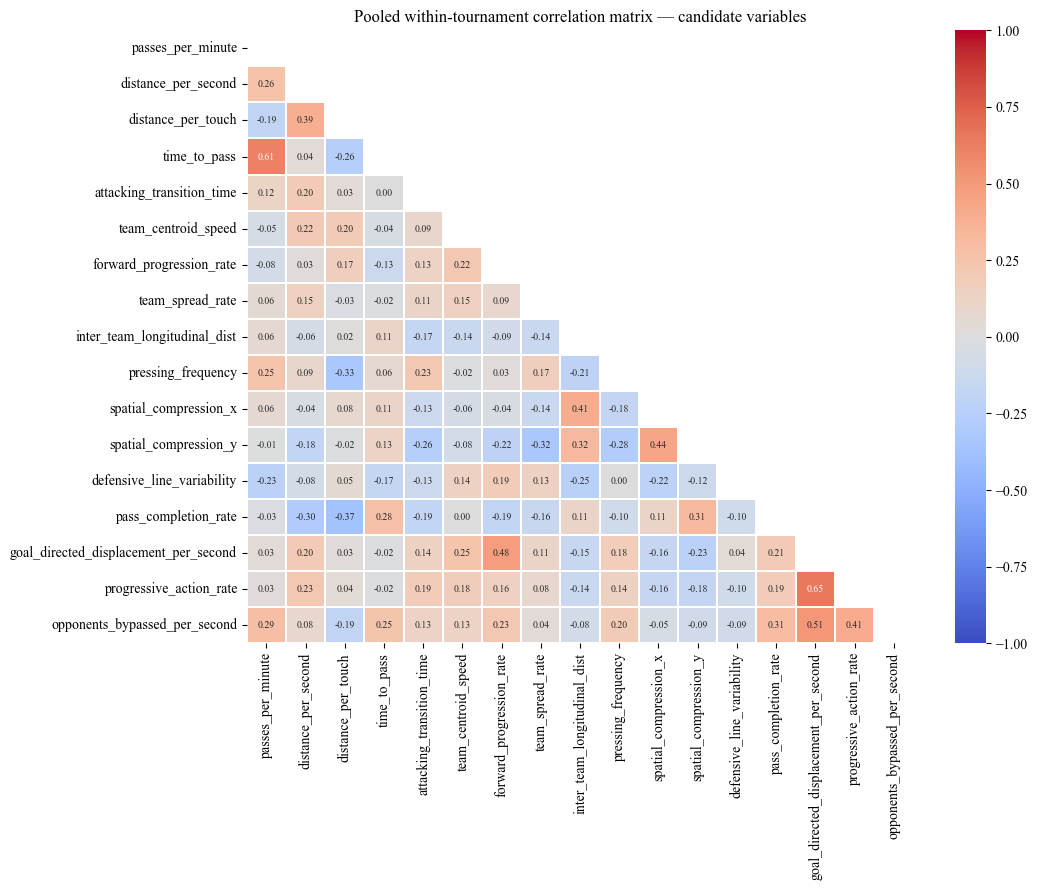

In [5]:
R_all = X_within[CANDIDATES].corr()
max_abs_r = R_all.abs().where(~np.eye(len(R_all), dtype=bool)).max()

redundant = set()
for i, a in enumerate(CANDIDATES):
    for b in CANDIDATES[i + 1:]:
        if a in redundant or b in redundant or abs(R_all.loc[a, b]) <= 0.80:
            continue
        redundant.add(b if max_abs_r[a] >= max_abs_r[b] else a)
        print(f"|r({a}, {b})| = {abs(R_all.loc[a, b]):.3f}")
SCREENED = [f for f in CANDIDATES if f not in redundant]
print(f"Redundant variables removed: {sorted(redundant) or 'none'}  → {len(SCREENED)} variables")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(R_all, mask=np.triu(np.ones_like(R_all, dtype=bool)), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7},
            linewidths=0.3, ax=ax)
ax.set_title("Pooled within-tournament correlation matrix — candidate variables", fontsize=12)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/FigureS1_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
kmo_items, kmo_total = calculate_kmo(X_within[SCREENED])
chi2, p_bartlett = calculate_bartlett_sphericity(X_within[SCREENED])
print(f"KMO = {kmo_total:.3f}   Bartlett χ² = {chi2:,.1f}, p = {p_bartlett:.1e}")
print(pd.Series(kmo_items, index=SCREENED, name="KMO").sort_values().round(3).to_string())

KMO = 0.665   Bartlett χ² = 190,015.8, p = 0.0e+00
forward_progression_rate                 0.522
pass_completion_rate                     0.545
passes_per_minute                        0.562
distance_per_touch                       0.602
time_to_pass                             0.611
distance_per_second                      0.629
goal_directed_displacement_per_second    0.641
defensive_line_variability               0.676
pressing_frequency                       0.687
progressive_action_rate                  0.711
spatial_compression_x                    0.722
team_spread_rate                         0.756
team_centroid_speed                      0.769
spatial_compression_y                    0.776
inter_team_longitudinal_dist             0.790
attacking_transition_time                0.794
opponents_bypassed_per_second            0.824


### 3.2 Iterative EFA (Supplementary Tables S4–S6)

In each iteration the number of factors is set by parallel analysis (95th percentile of the
eigenvalues of 200 random normal data sets) and a minimum-residual EFA with promax rotation is
fitted. All variables violating a retention criterion — communality h² < 0.30, primary loading
|λ| < 0.40, or difference between the two highest loadings < 0.15 — are removed together before
refitting.

In [7]:
H2_MIN, LOADING_MIN, CROSS_MIN = 0.30, 0.40, 0.15


def parallel_analysis(data, n_perm=200, seed=42):
    n, p = data.shape
    obs = np.linalg.eigvalsh(np.corrcoef(data.values, rowvar=False))[::-1]
    rng = np.random.default_rng(seed)
    rand = np.array([np.linalg.eigvalsh(np.corrcoef(rng.standard_normal((n, p)).T))[::-1]
                     for _ in range(n_perm)])
    return int((obs > np.percentile(rand, 95, axis=0)).sum())


def retention_violations(L, h2):
    out = {}
    for v in L.index:
        top = L.loc[v].abs().sort_values(ascending=False)
        why = []
        if h2[v] < H2_MIN:
            why.append(f"h² = {h2[v]:.2f} < {H2_MIN}")
        if top.iloc[0] < LOADING_MIN:
            why.append(f"max|λ| = {top.iloc[0]:.2f} < {LOADING_MIN}")
        if len(top) > 1 and top.iloc[0] - top.iloc[1] < CROSS_MIN:
            why.append(f"Δ = {top.iloc[0] - top.iloc[1]:.2f} < {CROSS_MIN}")
        if why:
            out[v] = why
    return out


items = list(SCREENED)
for it in range(1, 21):
    n_fac = max(parallel_analysis(X_within[items]), 2)
    fa = FactorAnalyzer(n_factors=n_fac, rotation="promax").fit(X_within[items])
    factors = [f"F{i + 1}" for i in range(n_fac)]
    L = pd.DataFrame(fa.loadings_, index=items, columns=factors)
    h2 = pd.Series(fa.get_communalities(), index=items)
    drop = retention_violations(L, h2)
    print(f"Iteration {it}: {len(items)} variables, {n_fac} factors")
    for v, why in drop.items():
        print(f"    exclude {v:<40s} {'; '.join(why)}")
    if not drop:
        break
    if len(items) - len(drop) < n_fac + 2:
        print("    stop: too few variables would remain")
        break
    items = [f for f in items if f not in drop]

FEATURES_FINAL = items
print(f"\nRetained ({len(FEATURES_FINAL)}): {FEATURES_FINAL}")

Iteration 1: 17 variables, 5 factors
    exclude attacking_transition_time                h² = 0.13 < 0.3; max|λ| = 0.29 < 0.4; Δ = 0.13 < 0.15
    exclude team_centroid_speed                      h² = 0.11 < 0.3; max|λ| = 0.25 < 0.4; Δ = 0.05 < 0.15
    exclude team_spread_rate                         h² = 0.12 < 0.3; max|λ| = 0.34 < 0.4
    exclude defensive_line_variability               h² = 0.16 < 0.3; max|λ| = 0.29 < 0.4; Δ = 0.08 < 0.15
    exclude pass_completion_rate                     Δ = 0.04 < 0.15
Iteration 2: 12 variables, 4 factors
    exclude forward_progression_rate                 h² = 0.22 < 0.3
    exclude pressing_frequency                       h² = 0.22 < 0.3; max|λ| = 0.38 < 0.4
Iteration 3: 10 variables, 4 factors
    exclude inter_team_longitudinal_dist             h² = 0.29 < 0.3
Iteration 4: 9 variables, 4 factors

Retained (9): ['passes_per_minute', 'distance_per_second', 'distance_per_touch', 'time_to_pass', 'spatial_compression_x', 'spatial_compression_y

In [8]:
# Factor labels (Supplementary Table S4): F1 directional progression, F2 passing tempo,
# F3 ball speed, F4 team spread
table_s4 = L.assign(h2=h2)
table_s5 = pd.DataFrame(fa.get_factor_variance(), columns=factors,
                        index=["SS loadings", "Variance explained (%)", "Cumulative variance (%)"])
table_s5.iloc[1:] *= 100
table_s6 = pd.DataFrame(fa.phi_, index=factors, columns=factors)

for name, tab in [("S4 · pattern matrix (promax) and communalities", table_s4),
                  ("S5 · factor-level statistics", table_s5),
                  ("S6 · factor correlations", table_s6)]:
    print(f"=== Table {name} ===\n{tab.round(3).to_string()}\n")
    tab.round(4).to_csv(f"{FIG_DIR}/Table{name.split(' ')[0]}_efa.csv")

=== Table S4 · pattern matrix (promax) and communalities ===
                                          F1     F2     F3     F4     h2
passes_per_minute                     -0.075  0.933  0.161 -0.048  0.905
distance_per_second                    0.072  0.278  0.744 -0.096  0.645
distance_per_touch                    -0.028 -0.216  0.635  0.120  0.465
time_to_pass                          -0.023  0.691 -0.076  0.101  0.493
spatial_compression_x                  0.004  0.058  0.088  0.632  0.410
spatial_compression_y                  0.000 -0.007 -0.077  0.707  0.506
goal_directed_displacement_per_second  0.903 -0.142  0.041 -0.005  0.838
progressive_action_rate                0.733 -0.105  0.094 -0.016  0.558
opponents_bypassed_per_second          0.602  0.222 -0.123  0.035  0.428

=== Table S5 · factor-level statistics ===
                             F1      F2      F3      F4
SS loadings               1.729   1.556   1.027   0.937
Variance explained (%)   19.206  17.288  11.416  10.4

## 4 · PPI construction (Horst weighting)

Each retained variable is weighted by the normalised column sum of the **signed** pooled
within-tournament correlation matrix (Eq. 1); the PPI is the weighted sum of the standardised
variables, z-standardised across the sample (Eq. 2):

$$w_j = \frac{\sum_k r_{jk}}{\sum_j\sum_k r_{jk}}, \qquad \mathrm{PPI}_i = \sum_j w_j z_{ij}$$

In [9]:
R = X_within[FEATURES_FINAL].corr()
w_horst = R.sum(axis=0)
w_horst = w_horst / w_horst.sum()

ppi_raw = Xz[FEATURES_FINAL].values @ w_horst.values
PPI = (ppi_raw - ppi_raw.mean()) / ppi_raw.std(ddof=0)

print("Horst weights:")
print(w_horst.sort_values(ascending=False).round(3).to_string())
print("\nPooled within-tournament correlations of the retained variables:")
print(R.round(3).to_string())

Horst weights:
opponents_bypassed_per_second            0.146
passes_per_minute                        0.138
goal_directed_displacement_per_second    0.134
progressive_action_rate                  0.132
distance_per_second                      0.131
time_to_pass                             0.121
spatial_compression_x                    0.084
distance_per_touch                       0.057
spatial_compression_y                    0.057

Pooled within-tournament correlations of the retained variables:
                                       passes_per_minute  distance_per_second  distance_per_touch  time_to_pass  spatial_compression_x  spatial_compression_y  goal_directed_displacement_per_second  progressive_action_rate  opponents_bypassed_per_second
passes_per_minute                                  1.000                0.262              -0.194         0.610                  0.065                 -0.006                                  0.034                    0.029                      

### EFA passing-tempo factor (for §6)

For comparison with the Horst composite (§6), regression-method factor scores of the final
EFA (weights from the within-tournament correlations, applied to the global z-scores) are
computed; the passing-tempo factor is the one with the highest loading on passes per minute.

In [ ]:
W_score = np.linalg.lstsq(np.corrcoef(X_within[FEATURES_FINAL].values, rowvar=False),
                          fa.loadings_, rcond=None)[0]
tempo_factor = int(L.loc["passes_per_minute"].abs().values.argmax())
EFA_tempo = (Xz[FEATURES_FINAL].values @ W_score)[:, tempo_factor]

### Save

`ppi` holds, for each analysed possession, the nine retained variables winsorised in their
natural units (inter-pass interval in s, not inverted) and as z-scores (`z_*`, oriented so that
higher = faster), the PPI and the EFA passing-tempo score.

In [11]:
ppi = meta.copy()
for f in FEATURES_FINAL:
    ppi[f] = -X_win[f] if f in INVERT else X_win[f]
for f in FEATURES_FINAL:
    ppi[f"z_{f}"] = Xz[f]
ppi["PPI"] = PPI
ppi["EFA_tempo"] = EFA_tempo
ppi = ppi.reset_index(drop=True)

ppi.to_hdf(OUT_H5, key="ppi", mode="a", complevel=5)
w_horst.rename("w").to_hdf(OUT_H5, key="horst_weights", mode="a")
print(f"Saved features / ppi / horst_weights → {OUT_H5}  ({len(ppi):,} possessions)")
print(ppi.groupby(["sex", "tournament"])["PPI"].agg(["count", "mean", "std"]).round(3).to_string())

Saved features / ppi / horst_weights → ../data/ppi-features.h5  (39,995 possessions)
                  count   mean    std
sex   tournament                     
Men   EURO2020     6740  0.117  0.950
      EURO2024     6456  0.123  0.976
      WC2022       8589  0.113  0.958
Women WEURO2022    4383 -0.107  1.009
      WEURO2025    4417 -0.122  1.004
      WWC2023      9410 -0.164  1.047


## 5 · Figure 1 — PPI by tournament

Raincloud plot: half-violin density, a random sample of 320 possessions per tournament, and a
boxplot (IQR, median, whiskers 1.5 × IQR; white dot = mean).

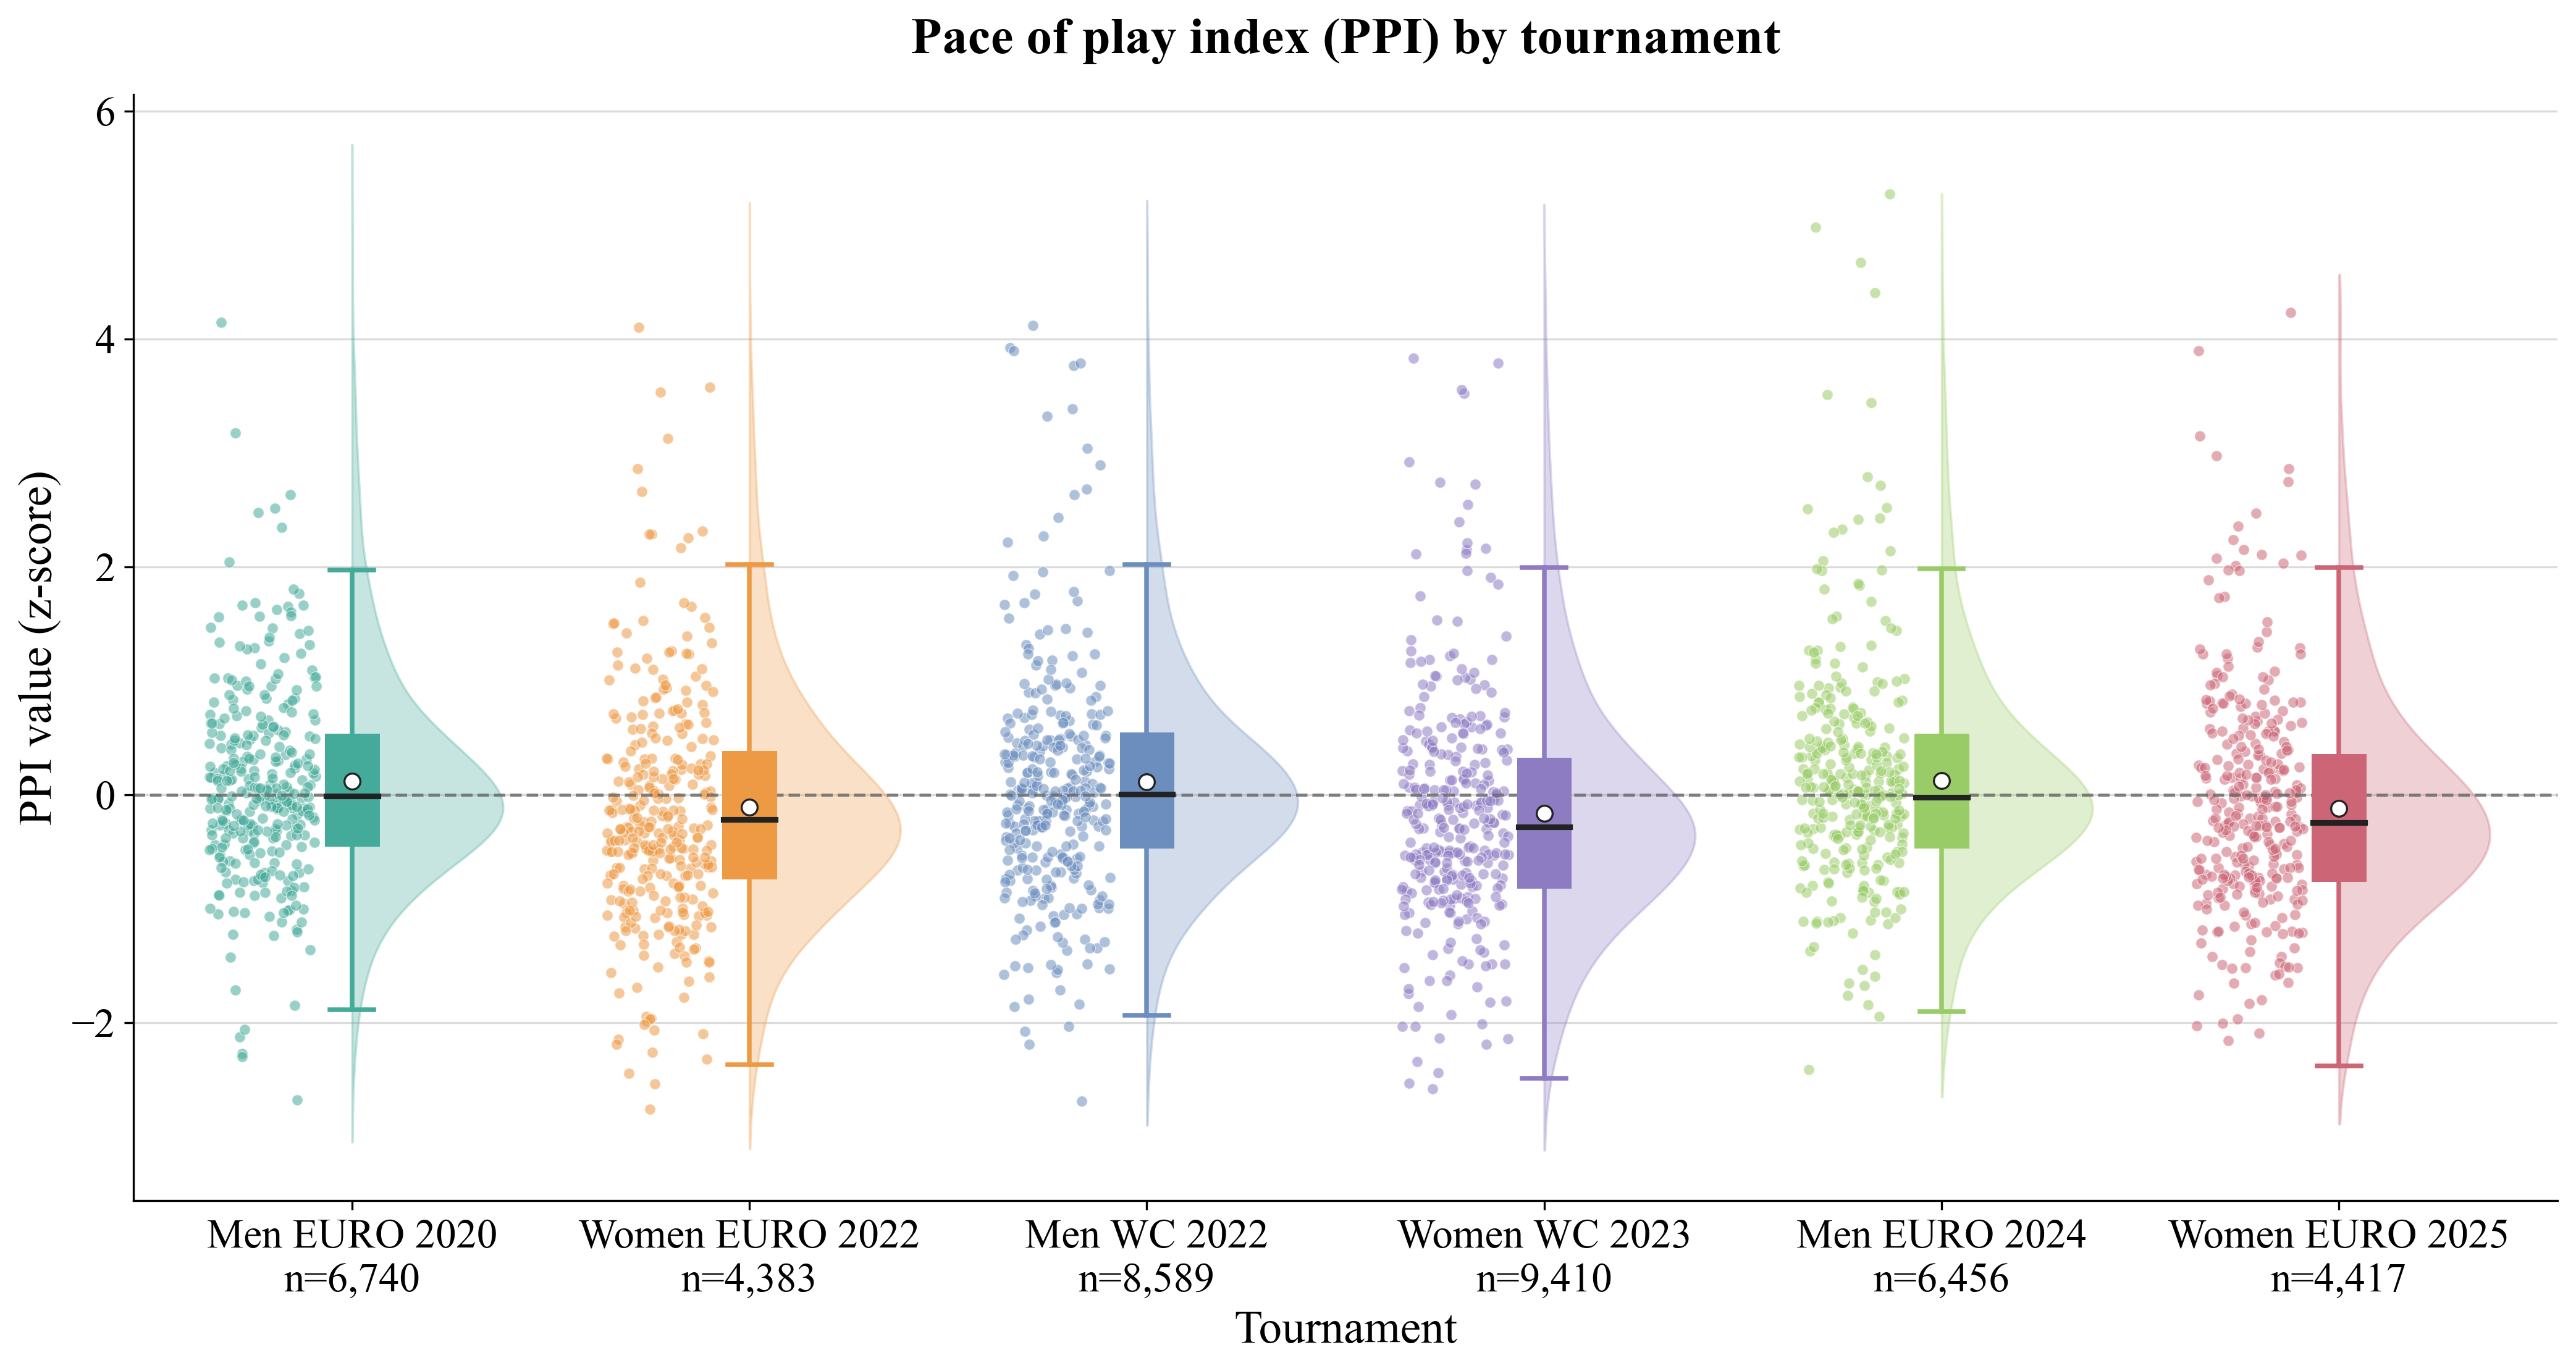

In [12]:
TOURN_LABELS = {"EURO2020": "Men EURO 2020", "WEURO2022": "Women EURO 2022",
                "WC2022": "Men WC 2022", "WWC2023": "Women WC 2023",
                "EURO2024": "Men EURO 2024", "WEURO2025": "Women EURO 2025"}
TOURN_COLOURS = {"EURO2020": "#44AA99", "WEURO2022": "#EE9944", "WC2022": "#6C8EBF",
                 "WWC2023": "#8E7CC3", "EURO2024": "#99CC66", "WEURO2025": "#CC6677"}
rng = np.random.default_rng(2025)

fig, ax = plt.subplots(figsize=(14, 7.5), dpi=300)
for x, tourn in enumerate(TOURN_LABELS):
    v = ppi.loc[ppi["tournament"] == tourn, "PPI"].to_numpy()
    col = TOURN_COLOURS[tourn]
    grid = np.linspace(v.min(), v.max(), 320)                       # cloud
    dens = gaussian_kde(v, bw_method=0.25)(grid)
    ax.fill_betweenx(grid, x, x + 0.38 * dens / dens.max(), color=col, alpha=0.30,
                     edgecolor=col, linewidth=0.9, zorder=1)
    rain = rng.choice(v, size=min(320, len(v)), replace=False)      # rain
    ax.scatter(x - rng.uniform(0.09, 0.36, size=len(rain)), rain, s=18, color=col,
               alpha=0.55, edgecolor="white", linewidth=0.35, zorder=2)
    q1, med, q3 = np.quantile(v, [0.25, 0.5, 0.75])                  # box
    lo, hi = v[v >= q1 - 1.5 * (q3 - q1)].min(), v[v <= q3 + 1.5 * (q3 - q1)].max()
    for y0, y1 in [(lo, q1), (q3, hi)]:
        ax.plot([x, x], [y0, y1], color=col, linewidth=1.8, zorder=3)
    for yw in (lo, hi):
        ax.plot([x - 0.055, x + 0.055], [yw, yw], color=col, linewidth=1.8, zorder=3)
    ax.add_patch(Rectangle((x - 0.065, q1), 0.13, q3 - q1, facecolor=col, edgecolor=col,
                           linewidth=1.2, zorder=4))
    ax.plot([x - 0.065, x + 0.065], [med, med], color="#222222", linewidth=2.2, zorder=5)
    ax.scatter(x, v.mean(), s=38, facecolor="white", edgecolor="#222222", linewidth=0.8, zorder=6)

ax.set_xticks(range(len(TOURN_LABELS)),
              [f"{lab}\nn={(ppi['tournament'] == t).sum():,}" for t, lab in TOURN_LABELS.items()])
ax.axhline(0, color="#666666", linestyle="--", linewidth=1.2, alpha=0.8)
ax.set_title("Pace of play index (PPI) by tournament", fontsize=20, fontweight="bold", pad=16)
ax.set_xlabel("Tournament", fontsize=18)
ax.set_ylabel("PPI value (z-score)", fontsize=18)
ax.tick_params(axis="both", labelsize=16)
ax.set_xlim(-0.55, len(TOURN_LABELS) - 0.45)
ax.grid(axis="y", color="#D0D0D0", linewidth=0.8, alpha=0.75)
ax.set_axisbelow(True)
sns.despine(ax=ax)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/Figure1_PPI_by_tournament.png", dpi=300, bbox_inches="tight")
plt.show()

## 6 · EFA passing-tempo factor vs Horst PPI by tournament (not in the manuscript)

Tournament means with 95% CIs from a match-level cluster bootstrap (B = 4,000).

tournament method   mean     lo     hi
  EURO2020    EFA  0.048  0.021  0.077
  EURO2020  Horst  0.117  0.075  0.160
    WC2022    EFA  0.044  0.014  0.075
    WC2022  Horst  0.113  0.075  0.149
  EURO2024    EFA  0.000 -0.037  0.038
  EURO2024  Horst  0.123  0.085  0.159
 WEURO2022    EFA -0.005 -0.067  0.056
 WEURO2022  Horst -0.107 -0.163 -0.057
   WWC2023    EFA -0.063 -0.094 -0.029
   WWC2023  Horst -0.164 -0.196 -0.130
 WEURO2025    EFA -0.021 -0.065  0.022
 WEURO2025  Horst -0.122 -0.162 -0.080


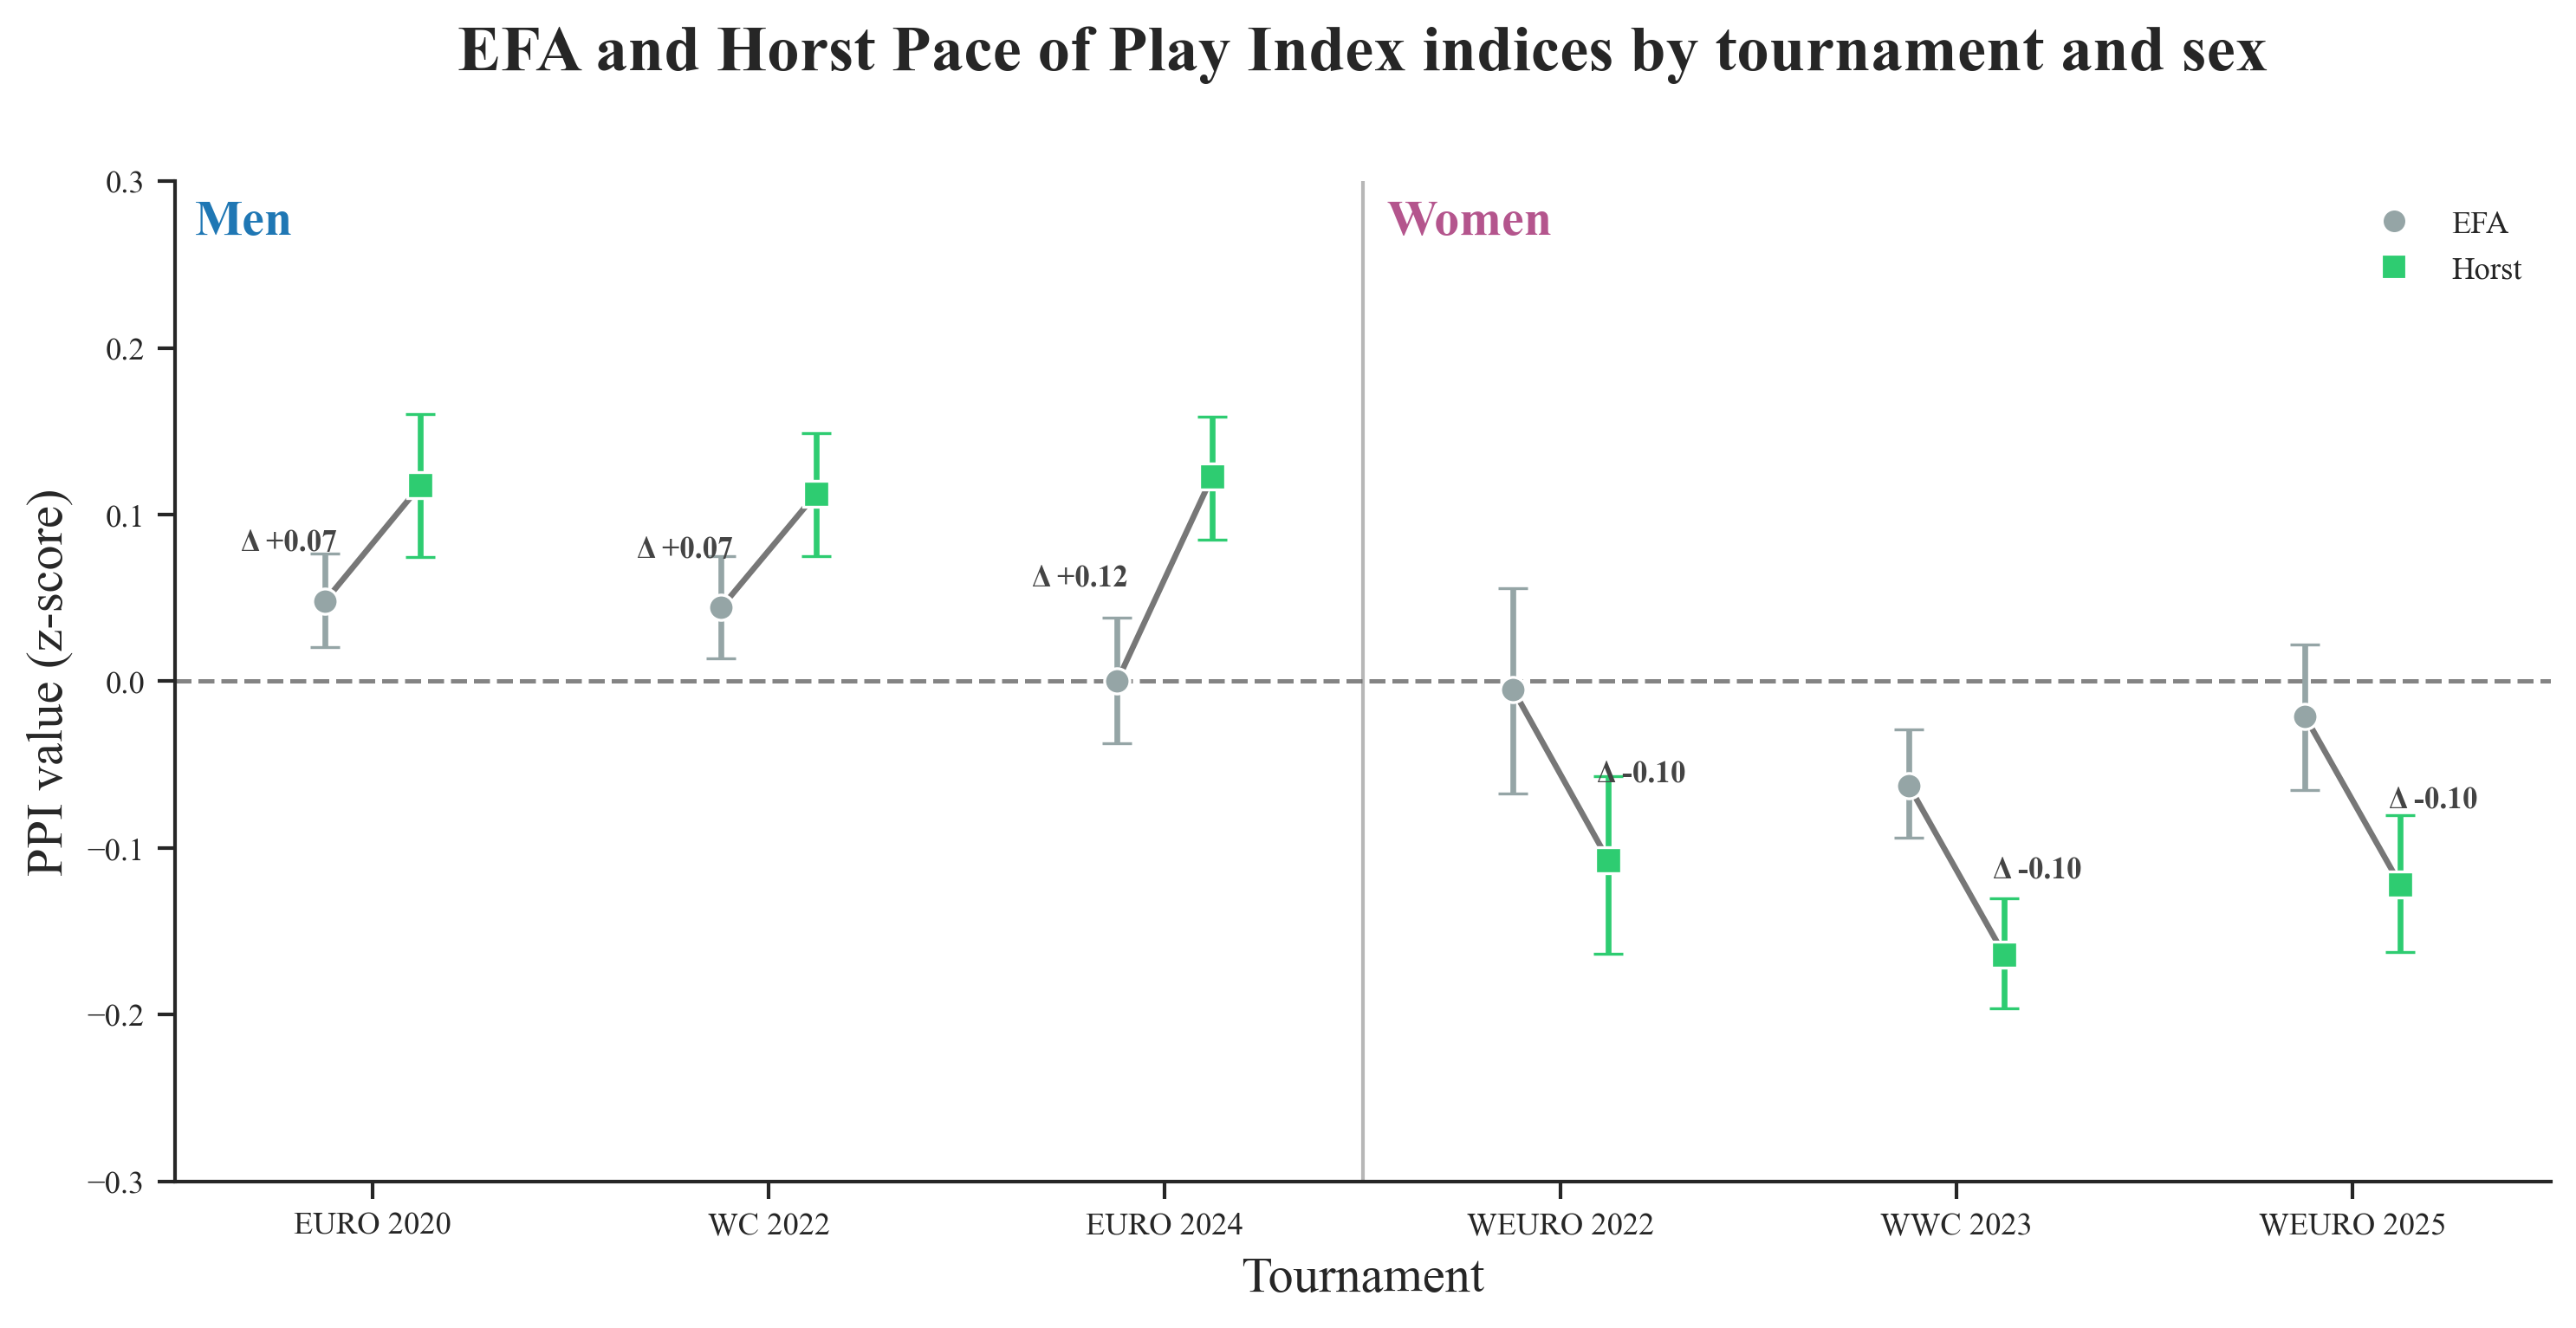

In [13]:
TOURN_FIG2 = ["EURO2020", "WC2022", "EURO2024", "WEURO2022", "WWC2023", "WEURO2025"]
INDEX_COLS = {"EFA": "EFA_tempo", "Horst": "PPI"}
COLORS = {"EFA": "#95a5a6", "Horst": "#2ecc71"}
rng = np.random.default_rng(2025)


def match_bootstrap_mean(sub, col, n_boot=4000):
    by_match = sub.groupby("game_id")[col].agg(["sum", "count"])
    idx = rng.integers(0, len(by_match), size=(n_boot, len(by_match)))
    boot = by_match["sum"].to_numpy()[idx].sum(1) / by_match["count"].to_numpy()[idx].sum(1)
    return (sub[col].mean(), *np.quantile(boot, [0.025, 0.975]))


fig2 = pd.DataFrame([(t, m, *match_bootstrap_mean(ppi[ppi["tournament"] == t], col))
                     for t in TOURN_FIG2 for m, col in INDEX_COLS.items()],
                    columns=["tournament", "method", "mean", "lo", "hi"])
print(fig2.round(3).to_string(index=False))

with sns.axes_style("ticks", rc={"font.family": "serif", "font.serif": ["Times New Roman"]}), \
        sns.plotting_context("paper"):
    fig, ax = plt.subplots(figsize=(10, 5.2), dpi=300)
    ax.axvline(2.5, color="#B7B7B7", linewidth=1.0, zorder=1)
    ax.axhline(0, color="#666666", linestyle="--", linewidth=1.2, alpha=0.8, zorder=1)
    for x, tourn in enumerate(TOURN_FIG2):
        pair = fig2[fig2["tournament"] == tourn].set_index("method")
        xe, xh = x - 0.12, x + 0.12
        ax.plot([xe, xh], pair["mean"].values, color="#777777", linewidth=1.6, zorder=2)
        for method, xm, marker in [("EFA", xe, "o"), ("Horst", xh, "s")]:
            r = pair.loc[method]
            ax.errorbar(xm, r["mean"], yerr=[[r["mean"] - r["lo"]], [r["hi"] - r["mean"]]],
                        fmt=marker, markersize=7, markerfacecolor=COLORS[method],
                        markeredgecolor="white", markeredgewidth=0.8, color=COLORS[method],
                        elinewidth=1.6, capsize=4, capthick=1.4, zorder=4)
        delta = pair.loc["Horst", "mean"] - pair.loc["EFA", "mean"]
        ax.annotate(f"Δ {delta:+.2f}", (x, pair["mean"].mean()),
                    xytext=(-10, 0) if x < 3 else (10, 0), textcoords="offset points",
                    ha="right" if x < 3 else "left", va="center", fontsize=8.5,
                    fontweight="bold", color="#444444", zorder=5)
    ax.text(-0.45, 0.98, "Men", transform=ax.get_xaxis_transform(), ha="left", va="top",
            fontsize=14, fontweight="bold", color="#1f77b4")
    ax.text(2.56, 0.98, "Women", transform=ax.get_xaxis_transform(), ha="left", va="top",
            fontsize=14, fontweight="bold", color="#b4558d")
    ax.set_xticks(range(6), ["EURO 2020", "WC 2022", "EURO 2024",
                             "WEURO 2022", "WWC 2023", "WEURO 2025"])
    ax.set_xlim(-0.5, 5.5)
    ax.set_ylim(-0.3, 0.3)
    ax.set_yticks(np.arange(-0.3, 0.31, 0.1))
    ax.set_xlabel("Tournament", fontsize=14)
    ax.set_ylabel("PPI value (z-score)", fontsize=14)
    ax.set_title("EFA and Horst Pace of Play Index indices by tournament and sex",
                 fontsize=18, pad=31, fontweight="bold")
    ax.legend(handles=[Line2D([0], [0], marker=m, color="none", markerfacecolor=COLORS[k],
                              markeredgecolor="white", label=k, markersize=7)
                       for k, m in [("EFA", "o"), ("Horst", "s")]],
              frameon=False, loc="upper right")
    sns.despine(ax=ax)
    plt.tight_layout()
    fig.savefig(f"{FIG_DIR}/EFA_vs_Horst_by_tournament.png", dpi=600, bbox_inches="tight")
    plt.show()